# 🌌 Equatorial Plasma Bubbles (EPB) Detection System — V4

## Two-Stage Cascaded Pipeline: Astronomical Sky Quality Control + 2DPCA Stacking Ensemble

### Key Methodological & Experimental Enhancements (WAIMLAP 2026 Revision):
- ✅ **Two-Stage Cascaded Architecture**: Stage 1 Astronomical Sky Quality Control (star-count & background brightness) + Stage 2 2DPCA + Stacking Ensemble (SVM RBF + XGBoost + Random Forest → Logistic Regression meta-learner).
- ✅ **Full 2DPCA Spectrum & Cross-Validated Component Selection ($k=1\dots 30$)**: Evaluates $k=5$ ($320$ features, $59.41\%$ cumulative variance on original training split / $56.5\%$ on augmented split) across the full 64-eigenvalue spectrum.
- ✅ **Leakage-Free 5-Fold Stratified CV & Temporal-Block Group CV**: Evaluates both stratified folds and 77 non-overlapping 30-minute observation blocks to eliminate temporal autocorrelation.
- ✅ **Comprehensive Baselines, Ablations & Cross-Station Generalization**: Benchmarks against 1D-PCA, flattened classifiers, a 2D-CNN baseline, Raw Images (no physics preprocessing), No-SMOTE, and Circular FOV Masking, including Zero-Shot transfer to Cachoeira Paulista (CP).
- ✅ **Hard Negatives & Stage 1 Cloud QC**: Evaluates high-lunar-illumination frames ($\ge 50\%$), per-observatory performance, zero-shot holdout on CP, and Stage 1 cloud rejection on overcast sequences.

### Evaluation protocol
The dataset has **7 observation nights** and every night contains a single class. Frame-level splits (stratified holdout, 5-fold stratified CV, 30-min block CV) put frames of the same night on both sides, so they measure how well the model recognises a night it has already seen. **The primary evaluation is leave-one-night-out (LOGO)**: every night is predicted by a model that never saw it. Frame-level results are kept as an optimistic reference and are labelled as such. The number of 2DPCA components is chosen under LOGO, and a confounder diagnosis tests whether night conditions (brightness, moon, corner text) predict the label.

---
**Author:** Alberto Ivo da Costa Vieira

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from epb_detection_system_v2 import (
    load_epb_dataset, augment_epb_data,
    optimize_n_components, plot_2dpca_variance,
    plot_performance_metrics, plot_confusion_matrix_analysis,
    plot_comprehensive_analysis, explain_feature_importance,
    analyze_threshold_sensitivity, plot_calibration_analysis,
    evaluate_kfold_cv, benchmark_baselines,
    evaluate_hard_negatives_and_generalization,
    plot_pipeline_architecture,
    explain_shap_importance, setup_logging,
    EPBRecognitionSystem, EPBModelData, save_model,
    benchmark_cv, plot_benchmark_cv, extract_night_groups,
    compare_n_components, diagnose_confounders
)

setup_logging()
FIGS_DIR = "../waimlap2026/epb/figs"
os.makedirs(FIGS_DIR, exist_ok=True)
RESULTS_DIR = "results_v4"                # Night-level evaluation outputs (figures + CSV)
os.makedirs(RESULTS_DIR, exist_ok=True)

In [2]:
# ========== CONFIGURATION ==========
DATA_FOLDER = "data/all-images"         # Folder with all labeled images
LABEL_FILE = "data/epb_labels.csv"      # CSV with ground-truth labels and metadata

TARGET_SIZE = (64, 64)                  # Downsampled image resolution
AUGMENT_FACTOR = 2                      # Stratified augmentation factor (applied strictly inside training splits)
BALANCE_METHOD = "smote"                # In-fold SMOTE balancing

N_COMPONENTS = 5                        # Default; re-selected below under leave-one-night-out
K_CANDIDATES = (5, 10, 25)              # 2DPCA components compared on unseen nights
ENSEMBLE_PARAMS = {
    "svm_C": 5.0,
    "svm_gamma": "scale",
    "xgb_n_estimators": 200,
    "xgb_max_depth": 6,
    "xgb_learning_rate": 0.1,
    "rf_n_estimators": 200,
    "rf_max_depth": 15,
    "meta_C": 1.0,
}

In [3]:
MODEL_VERSION = "4.0"
np.random.seed(42)

print("="*70)
print("🌌 EPB DETECTION SYSTEM — V4 (COMPLETE BENCHMARK & EVALUATION)")
print("="*70)

df_labels = pd.read_csv(LABEL_FILE)

# 1. Standard Physics-Informed Preprocessed Dataset
X, y, filenames = load_epb_dataset(
    data_folder=DATA_FOLDER,
    label_file=LABEL_FILE,
    target_size=TARGET_SIZE,
    apply_preprocessing=True,
    apply_circular_mask=False
)

# 2. Raw Dataset (without CLAHE/Gaussian/Star-removal) for Ablation Study
X_raw, _, _ = load_epb_dataset(
    data_folder=DATA_FOLDER,
    label_file=LABEL_FILE,
    target_size=TARGET_SIZE,
    apply_preprocessing=False,
    apply_circular_mask=False
)

# 3. Circular FOV Masked Dataset (removes corner text overlays) for Confounder Ablation
X_masked, _, _ = load_epb_dataset(
    data_folder=DATA_FOLDER,
    label_file=LABEL_FILE,
    target_size=TARGET_SIZE,
    apply_preprocessing=True,
    apply_circular_mask=True
)

# Stratified 75/25 Split (preserving indices for all dataset variants)
indices = np.arange(len(X))
train_idx, test_idx = train_test_split(
    indices, test_size=0.25, random_state=42, stratify=y
)

X_train_orig, X_test = X[train_idx], X[test_idx]
y_train_orig, y_test = y[train_idx], y[test_idx]
files_train = [filenames[i] for i in train_idx]
files_test = [filenames[i] for i in test_idx]

X_train_raw, X_test_raw = X_raw[train_idx], X_raw[test_idx]
X_train_masked, X_test_masked = X_masked[train_idx], X_masked[test_idx]

print(f"\n📦 Stratified Holdout Split (75%/25%):")
print(f"   • Train (original): {len(X_train_orig)} images (EPB: {int(y_train_orig.sum())}, No EPB: {int(len(y_train_orig) - y_train_orig.sum())})")
print(f"   • Test  (original): {len(X_test)} images (EPB: {int(y_test.sum())}, No EPB: {int(len(y_test) - y_test.sum())})")


INFO: Carregando dataset de EPBs...


INFO: Labels carregados: 572 registros


🌌 EPB DETECTION SYSTEM — V4 (COMPLETE BENCHMARK & EVALUATION)


INFO: 572 imagens carregadas com sucesso


INFO: Dimensão das imagens: 64x64


INFO: Distribuição das classes:


... (13 outputs left out)

INFO: Distribuição das classes:


INFO:   EPBs detectados: 255 (44.6%)


INFO:   No EPB: 317 (55.4%)



📦 Stratified Holdout Split (75%/25%):
   • Train (original): 429 images (EPB: 191, No EPB: 238)
   • Test  (original): 143 images (EPB: 64, No EPB: 79)


In [4]:
# ========== OBSERVATION NIGHTS (independent evaluation units) ==========
# A night crosses 00:00 UT: frames before 12:00 UT belong to the night that started the previous day.
night_groups = extract_night_groups(df_labels)

df_nights = (pd.DataFrame({"night": night_groups, "has_epb": y,
                           "cloudy": df_labels["cloudy"].values,
                           "moon": df_labels["moon_illumination"].values})
             .groupby("night")
             .agg(frames=("has_epb", "size"), epb_frames=("has_epb", "sum"),
                  cloudy_frames=("cloudy", "sum"), mean_moon_pct=("moon", "mean")))
df_nights["class"] = np.where(df_nights["epb_frames"] == df_nights["frames"], "EPB",
                              np.where(df_nights["epb_frames"] == 0, "No EPB", "mixed"))
print(f"{len(df_nights)} observation nights:")
print(df_nights.round(1).to_string())
n_mixed = int((df_nights["class"] == "mixed").sum())
print(f"\nNights containing both classes: {n_mixed}. "
      "Frame-level splits therefore let the model match test frames to their own night.")

7 observation nights:
              frames  epb_frames  cloudy_frames  mean_moon_pct   class
night                                                                 
BJL_20250722     220           0              0            3.8  No EPB
CA_20250407       35           0              0           80.4  No EPB
CA_20251022       85          85              0            2.2     EPB
CA_20251027       42          42              0           34.3     EPB
CA_20251218       86          86              0            1.1     EPB
CA_20260624       62           0             62           80.6  No EPB
CP_20240209       42          42              0            0.2     EPB

Nights containing both classes: 0. Frame-level splits therefore let the model match test frames to their own night.


💾 Pipeline architecture diagram saved: ../waimlap2026/epb/figs/pipeline_architecture.png (300 DPI)


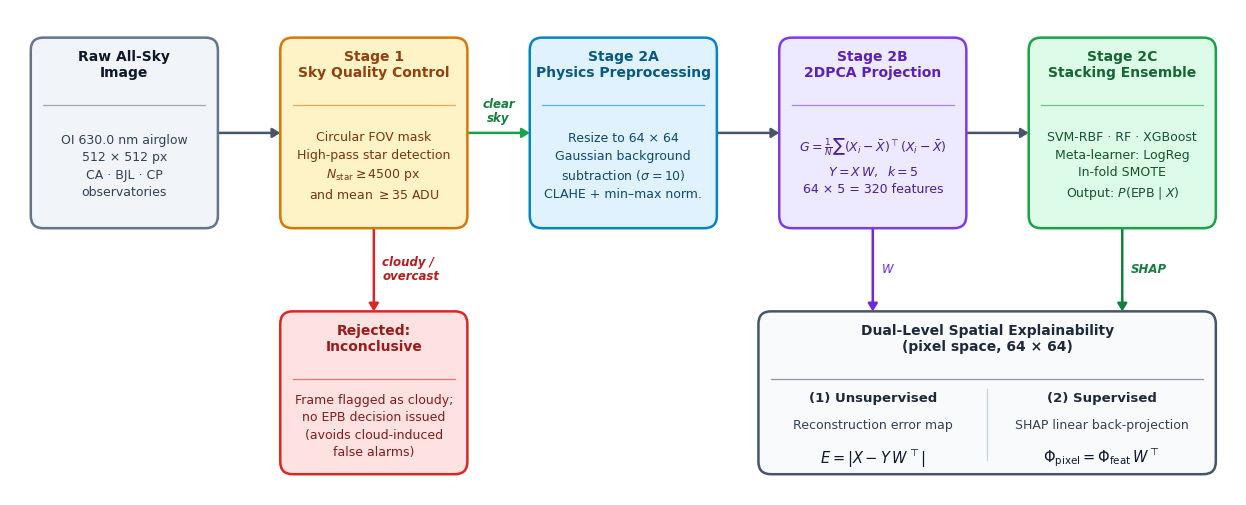

In [5]:
# ========== PIPELINE ARCHITECTURE DIAGRAM ==========
fig_arch = plot_pipeline_architecture(
    save_path=f"{FIGS_DIR}/pipeline_architecture.png",
    dpi=300
)


### 2DPCA component selection on unseen nights
`optimize_n_components` (next cell) scores an SVM proxy with frame-level folds, which rewards memorising nights. The value used by the system is chosen here with the **full stacking system under leave-one-night-out**: the smallest $k$ is kept unless a larger $k$ is significantly better (exact McNemar test, $\alpha=0.05$).

In [6]:
# ========== 2DPCA k SELECTION — FULL SYSTEM, LEAVE-ONE-NIGHT-OUT ==========
k_selection = compare_n_components(
    X, y,
    k_values=K_CANDIDATES,
    reference_k=min(K_CANDIDATES),
    protocol="logo",
    groups=night_groups,
    ensemble_params=ENSEMBLE_PARAMS,
)
N_COMPONENTS = k_selection["selected_k"]
print(f"\n➜ N_COMPONENTS = {N_COMPONENTS} ({64 * N_COMPONENTS} features)")
print(k_selection["summary"][["model", "accuracy", "sensitivity", "specificity",
                              "macro_night_accuracy", "worst_night_accuracy"]].round(3).to_string(index=False))

INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...


INFO: Variância explicada: 55.36%


INFO: Extraindo features...


INFO: Shape das features: (352, 320)


INFO: Normalizando features...


... (418 outputs left out)

INFO: Classe 0: 317 → 317


INFO: Classe 1: 213 → 317


INFO: Treinamento concluído!


   ✓ split 0.6 done (train=530, test=42)

----------------------------------------------------------------------------------------
Leave-one-group-out (7 groups)
----------------------------------------------------------------------------------------
Model                                      Acc    Sens    Spec      F1     AUC  MacroNight   Worst
k=5                                     0.3654  0.7725  0.0379  0.5205  0.1412      0.4947  0.0161
k=10                                    0.3374  0.7216  0.0284  0.4926  0.1050      0.4365  0.0161
k=25                                    0.2762  0.6157  0.0032  0.4313  0.0678      0.3500  0.0000

Significance vs. 'k=5':
model  mcnemar_ref_only  mcnemar_other_only  p_mcnemar
 k=10                22                   6     0.0037
 k=25                56                   5     0.0000

🔬 n_components significance test (full stacking system, paired folds):
   • k=10 vs k=5: McNemar p=0.0037 -> not significantly better
   • k=25 vs k=5: McNemar p=

INFO: Otimizando número de componentes (máx=30)...


INFO:    1 comp: F1=0.9552±0.0184 | Var=22.86%


INFO:    2 comp: F1=0.9733±0.0150 | Var=37.99%


INFO:    3 comp: F1=0.9708±0.0135 | Var=46.27%


INFO:    5 comp: F1=0.9663±0.0135 | Var=59.41%


INFO:   10 comp: F1=0.9714±0.0125 | Var=79.03%


... (28 outputs left out)

INFO: Classe 0: 476 → 573


INFO: Classe 1: 573 → 573


INFO: Treinamento concluído!


💾 Figure saved: ../waimlap2026/epb/figs/2dpca_variance.png (300 DPI)


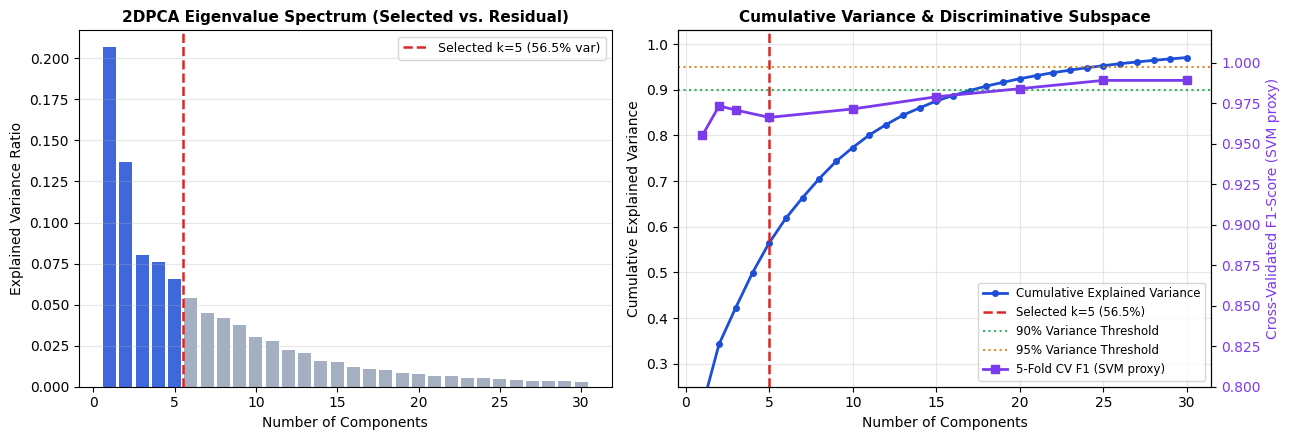

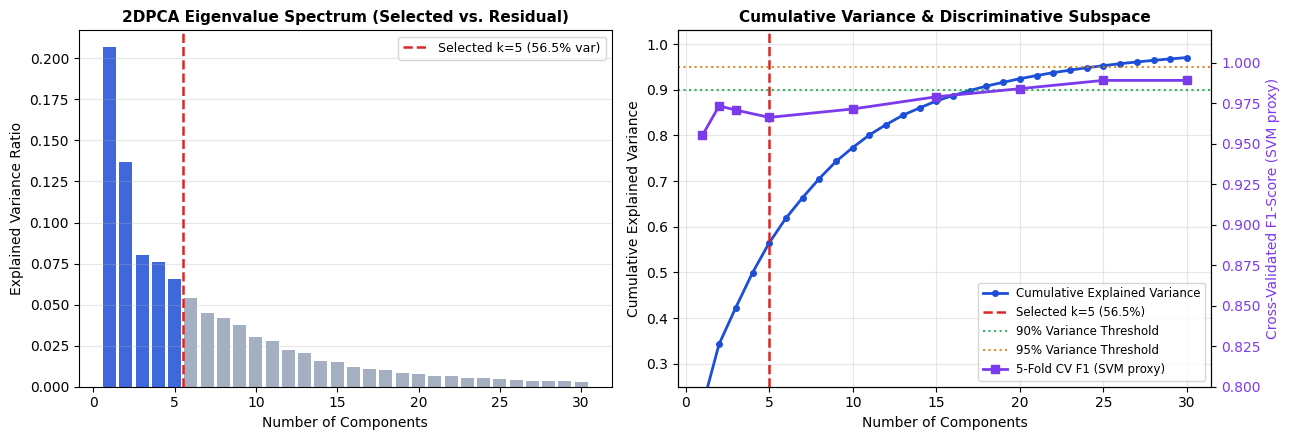

In [7]:
# ========== FRAME-LEVEL k SCAN (SVM proxy, reference only) & EIGENVALUE SPECTRUM ==========
# Frame-level folds: optimistic; N_COMPONENTS was selected above under leave-one-night-out.
best_k, cv_comp_results = optimize_n_components(
    X_train_orig, y_train_orig,
    max_components=30,
    cv_folds=5,
    use_augmentation=False
)

# Augment training split only
X_train, y_train = augment_epb_data(X_train_orig, y_train_orig, augment_factor=AUGMENT_FACTOR)

# Fit full system
system = EPBRecognitionSystem(
    n_components=N_COMPONENTS,
    balance_data=True,
    balance_method=BALANCE_METHOD,
    ensemble_params=ENSEMBLE_PARAMS,
)
system.fit(X_train, y_train)

# Plot full 30-component eigenvalue spectrum + 5-Fold CV F1 curve
plot_2dpca_variance(
    system,
    cv_component_results=cv_comp_results,
    max_display_components=30,
    save_path=f"{FIGS_DIR}/2dpca_variance.png",
    dpi=300
)

In [8]:
# ========== FRAME-LEVEL HOLDOUT (n=143) — OPTIMISTIC REFERENCE ==========
# Random 75/25 split by frame: every test night also appears in training.
print("="*70)
print("FRAME-LEVEL HOLDOUT (n=143) — optimistic: test nights also seen in training")
print("="*70)

y_pred = system.predict(X_test)
y_proba = system.predict_proba(X_test)

print(classification_report(y_test, y_pred, target_names=["No EPB", "EPB"], digits=4))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
npv = tn / (tn + fn) if (tn + fn) > 0 else 0

print(f"   • Sensitivity (Recall EPB):  {sensitivity*100:.2f}%")
print(f"   • Specificity:               {specificity*100:.2f}%")
print(f"   • PPV (Precision EPB):       {ppv*100:.2f}%")
print(f"   • NPV:                       {npv*100:.2f}%")

FRAME-LEVEL HOLDOUT (n=143) — optimistic: test nights also seen in training
              precision    recall  f1-score   support

      No EPB     0.9625    0.9747    0.9686        79
         EPB     0.9683    0.9531    0.9606        64

    accuracy                         0.9650       143
   macro avg     0.9654    0.9639    0.9646       143
weighted avg     0.9651    0.9650    0.9650       143

   • Sensitivity (Recall EPB):  95.31%
   • Specificity:               97.47%
   • PPV (Precision EPB):       96.83%
   • NPV:                       96.25%


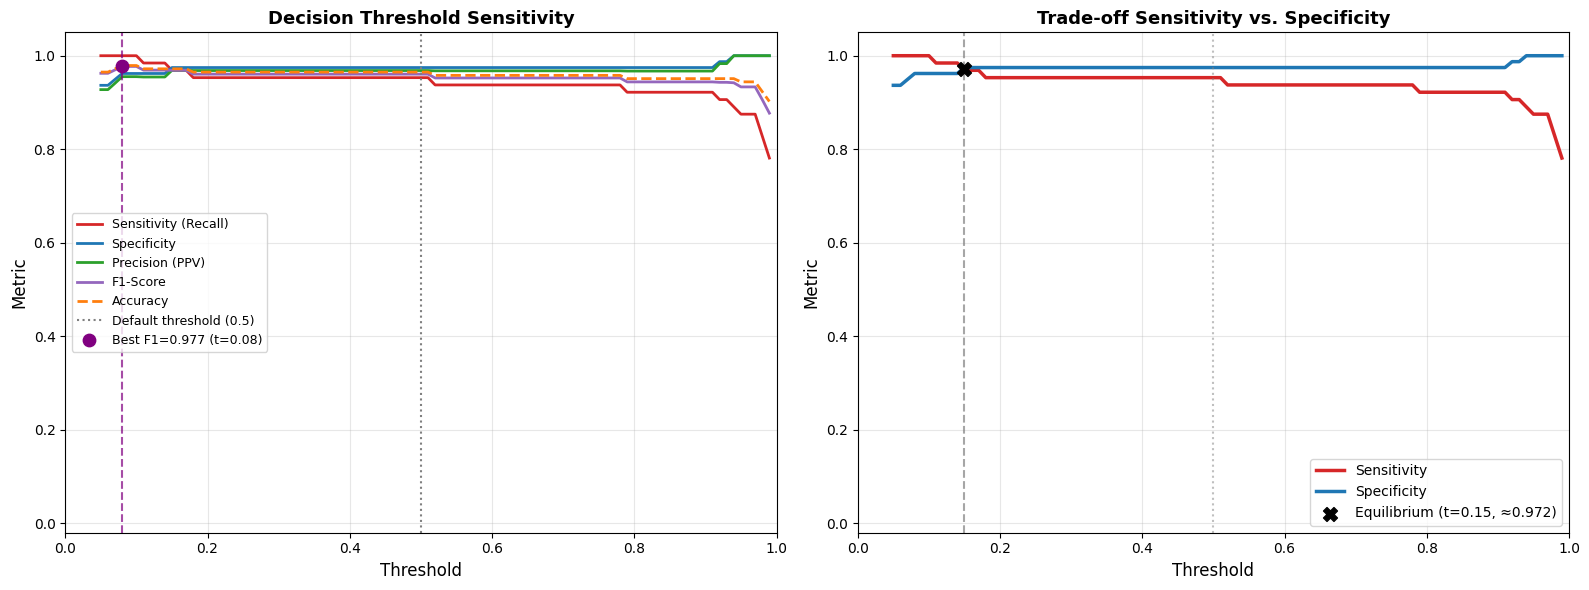


📊 ANÁLISE DE SENSIBILIDADE AO THRESHOLD

   Metric                   t=0.50      Best F1  Equilibrium
   --------------------------------------------------------
   Threshold                  0.50         0.08         0.15
   Sensitivity              0.9531       1.0000       0.9688
   Specificity              0.9747       0.9620       0.9747
   Precision                0.9683       0.9552       0.9688
   F1-Score                 0.9606       0.9771       0.9688
   Accuracy                 0.9650       0.9790       0.9720

   💡 Recomendação:
      O melhor F1 ocorre em t=0.08 (< 0.50) — o threshold padrão
      é conservador. Baixar o threshold aumenta a detecção de EPBs.



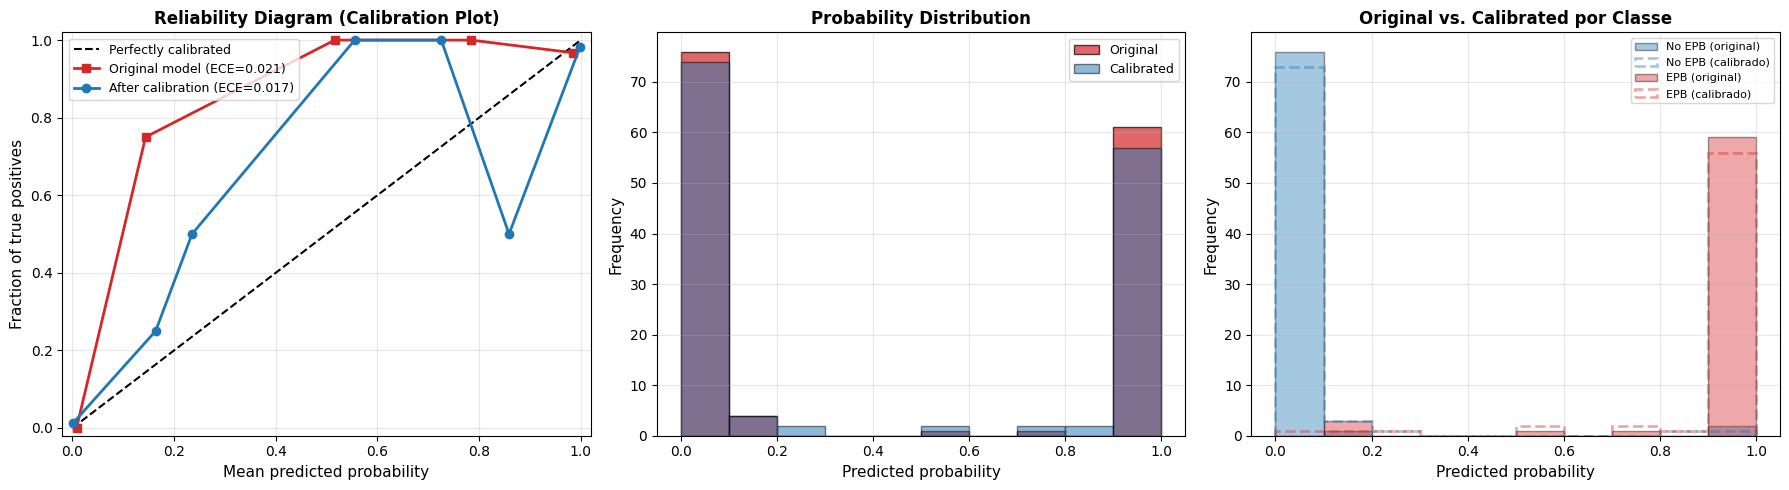


📊 ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES

   ECE original (Expected Calibration Error): 0.0212
   ✓ Probabilidades bem calibradas
   ECE após calibração isotónica:              0.0172
   ⚠️  Calibração não trouxe melhoria significativa (Δ=0.0040)

   💡 Interpretação do reliability diagram:
      Se os pontos ficam ACIMA da diagonal: modelo é subconfiante
        (diz 60%, mas na verdade 80% são positivos)
      Se os pontos ficam ABAIXO da diagonal: modelo é sobreconfiante
        (diz 80%, mas na verdade só 60% são positivos)



In [9]:
# ========== THRESHOLD SENSITIVITY & PROBABILITY CALIBRATION ==========
fig_threshold, df_thresholds = analyze_threshold_sensitivity(y_test, y_proba)

X_train_feat = system.scaler.transform(system.extract_features(X_train))
X_test_feat = system.scaler.transform(system.extract_features(X_test))

fig_cal, cal_stats = plot_calibration_analysis(
    y_true=y_test,
    y_proba=y_proba,
    system=system,
    X_train_features=X_train_feat,
    y_train=y_train,
    X_test_features=X_test_feat,
)


INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...


INFO: Variância explicada: 59.74%


INFO: Extraindo features...


INFO: Shape das features: (457, 320)


INFO: Normalizando features...


... (97 outputs left out)

   Fold 4/5 (n=114): Acc=0.9561 | Sens=0.9216 | Spec=0.9841 | Prec=0.9792 | F1=0.9495 | ROC-AUC=0.9978 | PR-AUC=0.9972


INFO: Treinamento concluído!


   Fold 5/5 (n=114): Acc=0.9561 | Sens=0.9020 | Spec=1.0000 | Prec=1.0000 | F1=0.9485 | ROC-AUC=0.9960 | PR-AUC=0.9953

📈 SUMMARY RESULTS: 5-Fold Stratified CV

   Metric                     Mean      ± Std        Min        Max
   ------------------------------------------------------------
   Accuracy                 0.9720     0.0157     0.9561     0.9913
   Sensitivity              0.9530     0.0451     0.9020     1.0000
   Specificity              0.9874     0.0132     0.9683     1.0000
   Precision                0.9845     0.0159     0.9623     1.0000
   F1                       0.9678     0.0186     0.9485     0.9903
   AUC                      0.9984     0.0016     0.9960     1.0000
   PR_AUC                   0.9980     0.0018     0.9953     1.0000


💾 Cross-validation figure saved: ../waimlap2026/epb/figs/kfold_cv_metrics.png (300 DPI)


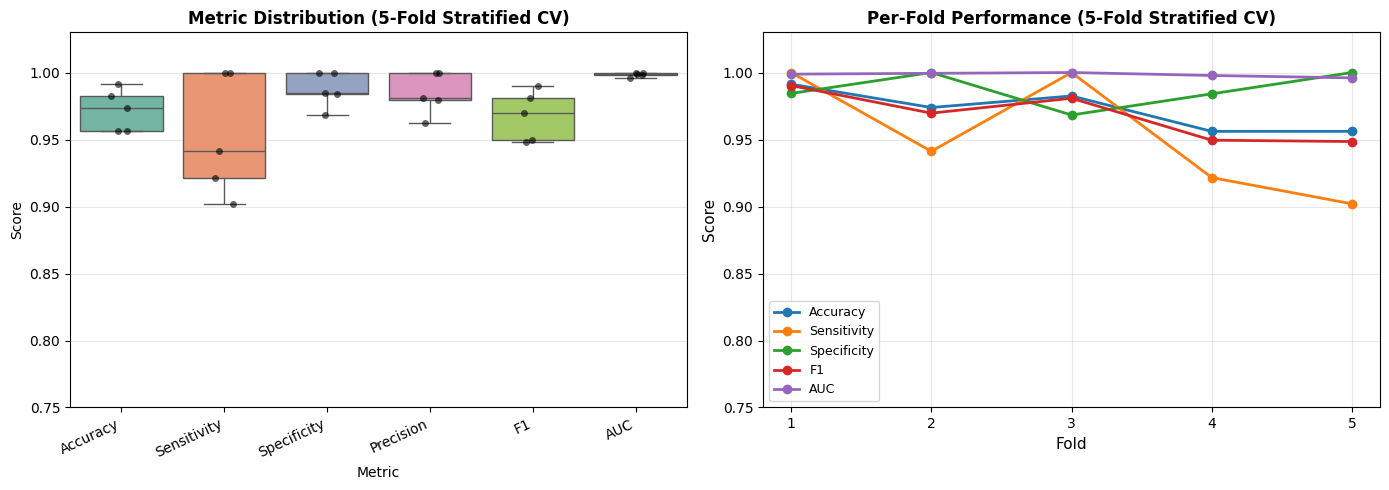

INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...


INFO: Variância explicada: 59.01%


INFO: Extraindo features...


INFO: Shape das features: (464, 320)


INFO: Normalizando features...


... (96 outputs left out)

INFO: Classe 1: 220 → 220


   Fold 4/5 (n=119): Acc=0.9664 | Sens=1.0000 | Spec=0.9394 | Prec=0.9298 | F1=0.9636 | ROC-AUC=1.0000 | PR-AUC=1.0000


INFO: Treinamento concluído!


   Fold 5/5 (n=134): Acc=0.9627 | Sens=0.8571 | Spec=1.0000 | Prec=1.0000 | F1=0.9231 | ROC-AUC=0.9994 | PR-AUC=0.9984

📈 SUMMARY RESULTS: 5-Fold Group CV (temporal_block, 77 groups)

   Metric                     Mean      ± Std        Min        Max
   ------------------------------------------------------------
   Accuracy                 0.9508     0.0572     0.8519     1.0000
   Sensitivity              0.9088     0.1048     0.7538     1.0000
   Specificity              0.9879     0.0271     0.9394     1.0000
   Precision                0.9860     0.0314     0.9298     1.0000
   F1                       0.9424     0.0537     0.8596     1.0000
   AUC                      0.9969     0.0066     0.9850     1.0000
   PR_AUC                   0.9978     0.0041     0.9906     1.0000


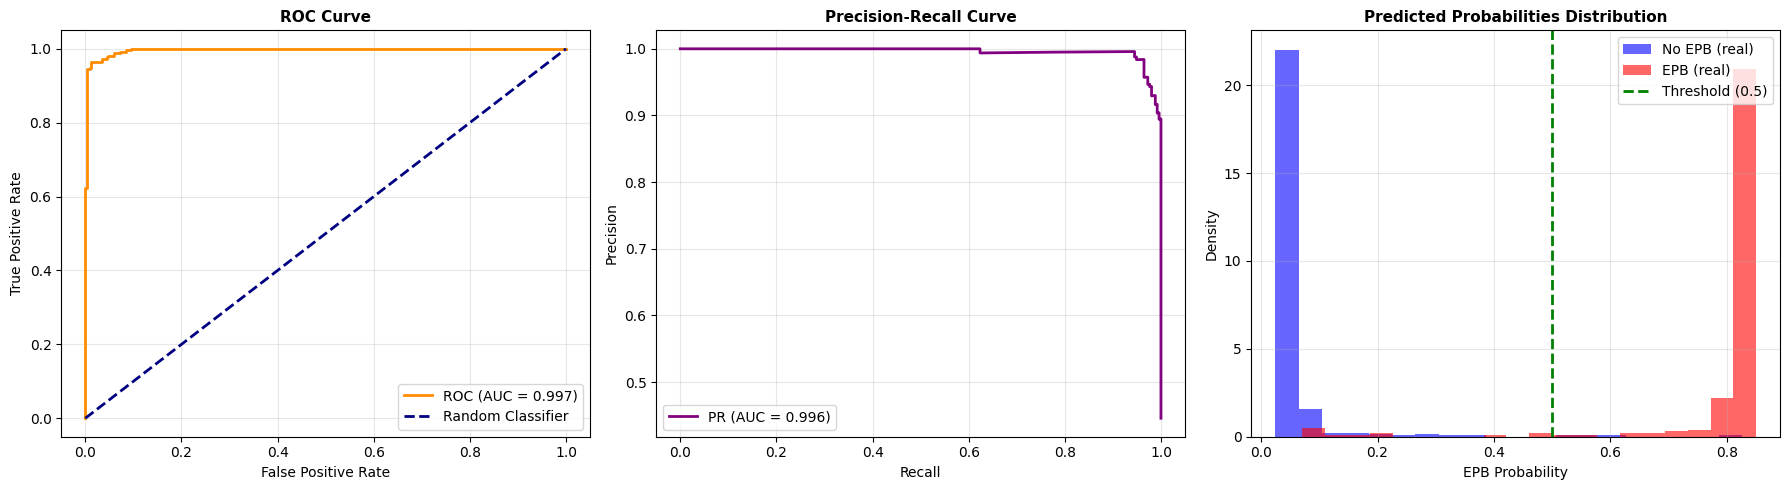

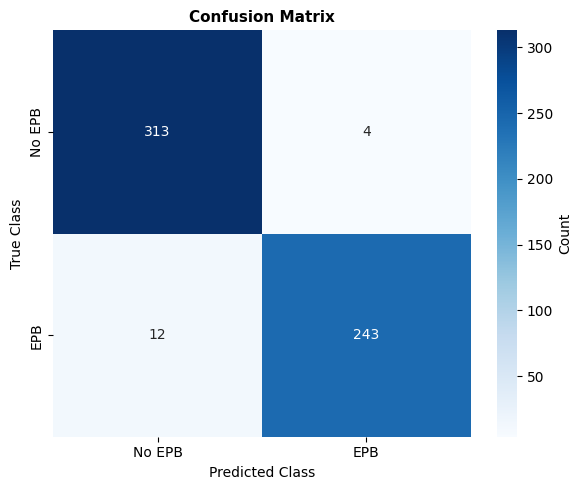

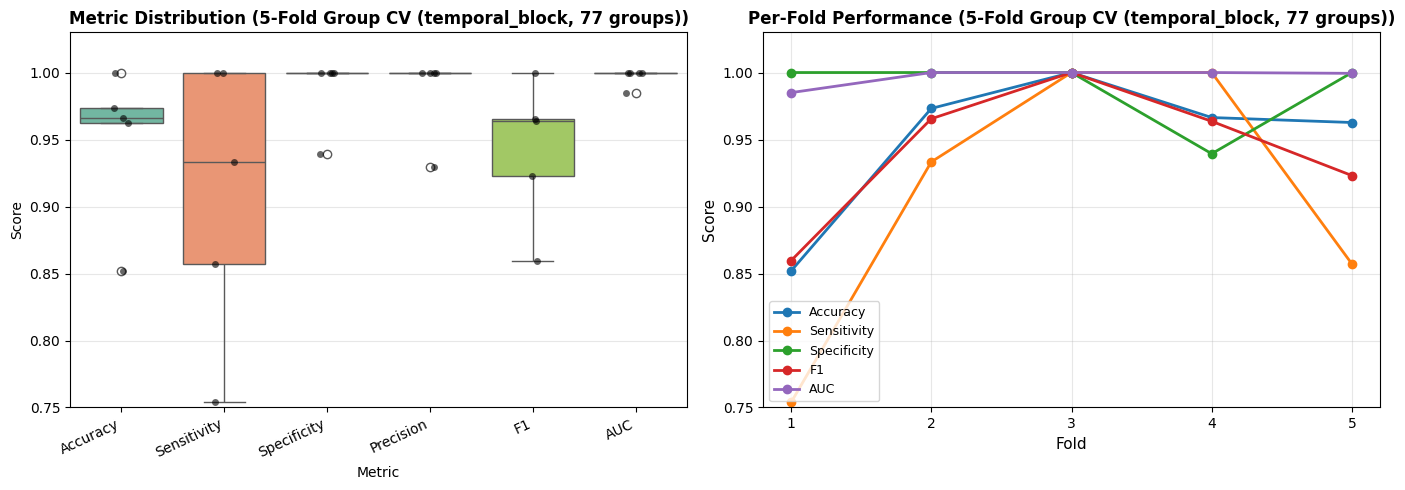

INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...


INFO: Variância explicada: 60.42%


INFO: Extraindo features...


INFO: Shape das features: (457, 320)


INFO: Normalizando features...


... (96 outputs left out)

INFO: Classe 1: 204 → 254


   Fold 4/5 (n=114): Acc=0.9386 | Sens=0.8824 | Spec=0.9841 | Prec=0.9783 | F1=0.9278 | ROC-AUC=0.9975 | PR-AUC=0.9969


INFO: Treinamento concluído!


   Fold 5/5 (n=114): Acc=0.9561 | Sens=0.9216 | Spec=0.9841 | Prec=0.9792 | F1=0.9495 | ROC-AUC=0.9963 | PR-AUC=0.9957

📈 SUMMARY RESULTS: 5-Fold Stratified CV

   Metric                     Mean      ± Std        Min        Max
   ------------------------------------------------------------
   Accuracy                 0.9580     0.0157     0.9386     0.9826
   Sensitivity              0.9334     0.0472     0.8824     1.0000
   Specificity              0.9779     0.0180     0.9524     1.0000
   Precision                0.9724     0.0215     0.9423     1.0000
   F1                       0.9516     0.0189     0.9278     0.9808
   AUC                      0.9976     0.0011     0.9963     0.9991
   PR_AUC                   0.9971     0.0012     0.9957     0.9988


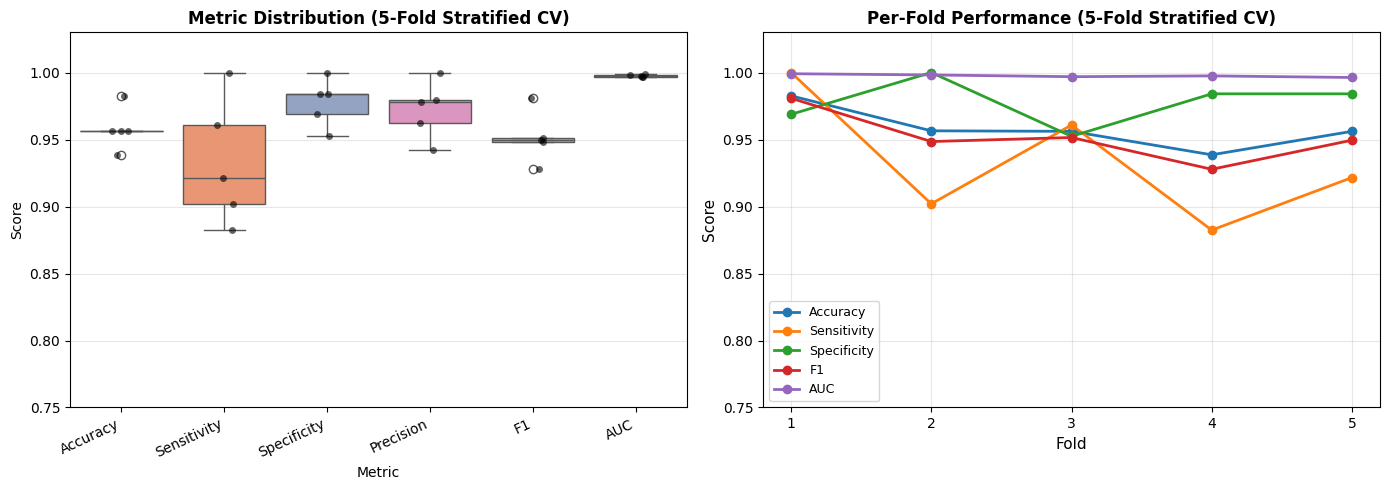

In [10]:
# ========== FRAME-LEVEL CV (OPTIMISTIC REFERENCE): STRATIFIED, 30-MIN BLOCKS, FOV MASK ==========
# All three protocols keep frames of the same night in train and test.
# The primary, night-level evaluation is in the next cell.
# 1. Standard 5-Fold Stratified Cross-Validation (Leakage-Free)
fig_kfold, df_kfold, oof_strat = evaluate_kfold_cv(
    X, y,
    n_components=N_COMPONENTS,
    n_folds=5,
    balance_method=BALANCE_METHOD,
    use_augmentation=False,
    ensemble_params=ENSEMBLE_PARAMS,
    group_by=None,
    return_oof=True,
    save_path=f"{FIGS_DIR}/kfold_cv_metrics.png",
    dpi=300
)

# Save Out-of-Fold ROC, PR, and Probability Distribution curves (N=572)
plot_performance_metrics(
    oof_strat["y_true"], oof_strat["y_proba"],
    save_path=f"{FIGS_DIR}/roc_pr_curves.png",
    dpi=300
)

# Save Out-of-Fold Confusion Matrix (N=572)
plot_confusion_matrix_analysis(
    oof_strat["y_true"], oof_strat["y_pred"],
    save_path=f"{FIGS_DIR}/confusion_matrix.png",
    dpi=300
)

# 2. 5-Fold Temporal-Block Group CV (77 non-overlapping 30-min observation blocks)
fig_tg_cv, df_tg_cv = evaluate_kfold_cv(
    X, y,
    n_components=N_COMPONENTS,
    n_folds=5,
    balance_method=BALANCE_METHOD,
    use_augmentation=False,
    ensemble_params=ENSEMBLE_PARAMS,
    group_by="temporal_block",
    df_metadata=df_labels,
    dpi=300
)

# 3. 5-Fold Circular FOV Mask Ablation CV (verifying corner text stamps do not drive accuracy)
fig_mask_cv, df_mask_cv = evaluate_kfold_cv(
    X_masked, y,
    n_components=N_COMPONENTS,
    n_folds=5,
    balance_method=BALANCE_METHOD,
    use_augmentation=False,
    ensemble_params=ENSEMBLE_PARAMS,
    group_by=None,
    dpi=300
)

### Primary evaluation — leave-one-night-out
Each of the observation nights is held out in turn and predicted by models trained on the remaining nights. All models (baselines, 2D-CNN, proposed system and ablations) use exactly the same splits. Because every night is single-class, metrics are computed on the pooled out-of-night predictions, and per-night accuracy is reported (sensitivity for EPB nights, specificity for quiet nights).


📊 PAIRED BENCHMARK — Leave-one-group-out (7 groups) | 13 models | 7 train/test splits


INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...


INFO: Variância explicada: 55.36%


INFO: Extraindo features...


INFO: Shape das features: (352, 320)


... (538 outputs left out)

INFO: Classe 1: 213 → 317


INFO: Treinamento concluído!


   ✓ split 0.6 done (train=530, test=42)

----------------------------------------------------------------------------------------
Leave-one-group-out (7 groups)
----------------------------------------------------------------------------------------
Model                                      Acc    Sens    Spec      F1     AUC  MacroNight   Worst
Flatten + LogReg                        0.7657  0.8392  0.7066  0.7616  0.7845      0.6570  0.0323
Flatten + Random Forest                 0.3776  0.8392  0.0063  0.5459  0.3404      0.4732  0.0000
1D-PCA + LogReg                         0.4563  0.6980  0.2618  0.5337  0.4372      0.5329  0.0000
1D-PCA + SVM (RBF)                      0.4458  1.0000  0.0000  0.6167  0.1538      0.5714  0.0000
2DPCA + LogReg                          0.4930  0.8902  0.1735  0.6102  0.4243      0.5622  0.0000
2DPCA + SVM (RBF)                       0.3864  0.8431  0.0189  0.5506  0.1880      0.5088  0.0000
2DPCA + Random Forest                   0.5472  0.8667  

💾 Benchmark figure saved: results_v4/benchmark_logo.png (300 DPI)


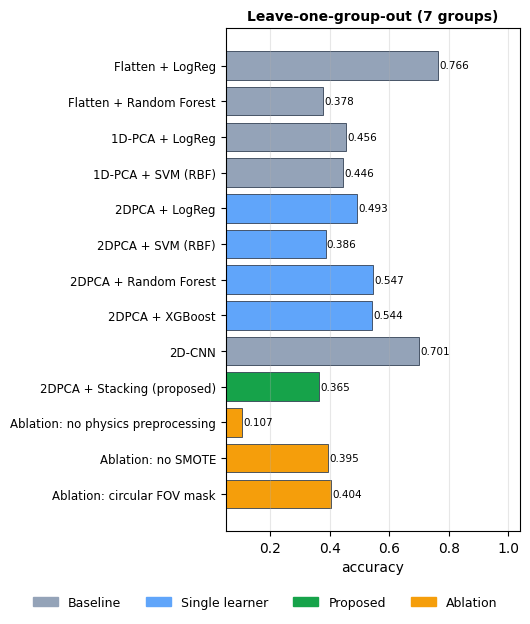

💾 Gráfico salvo: results_v4/roc_pr_curves_logo.png (300 DPI)
💾 Gráfico salvo: results_v4/confusion_matrix_logo.png (300 DPI)


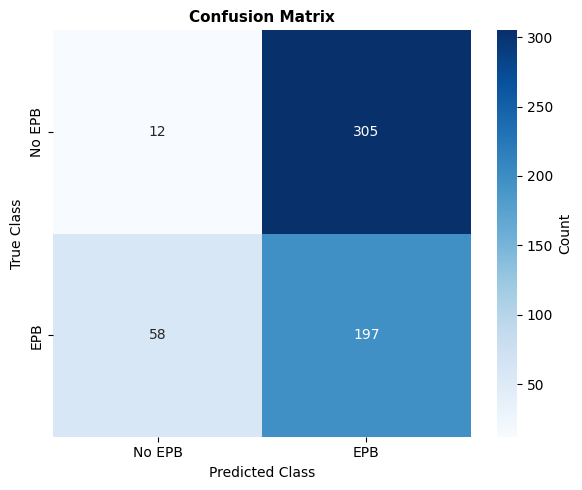

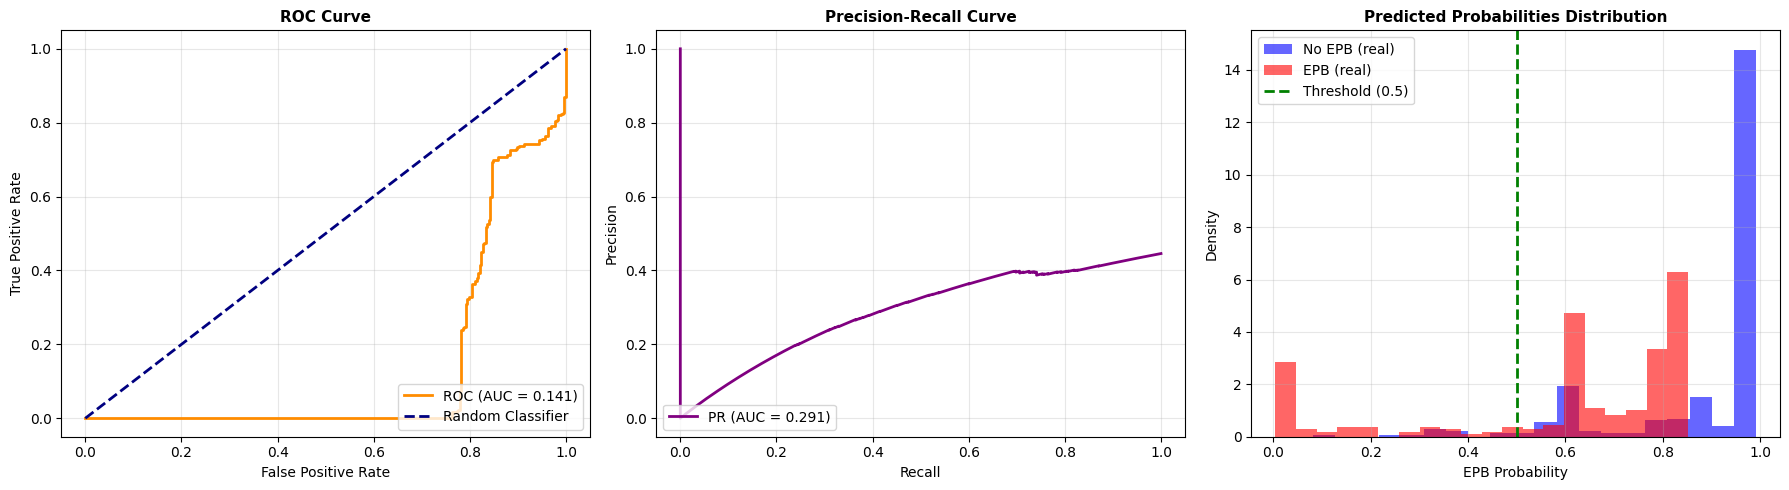

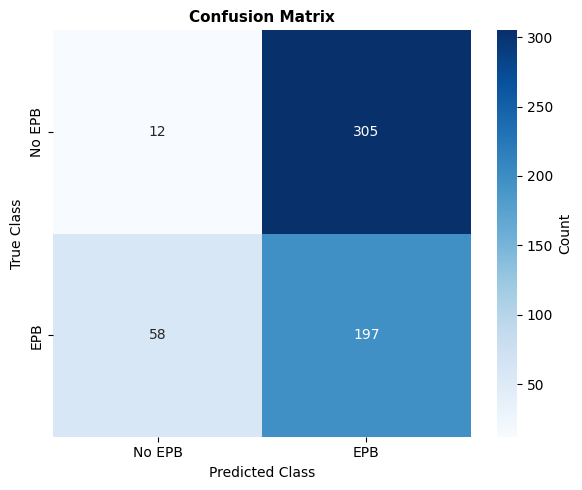

In [11]:
# ========== PRIMARY EVALUATION: LEAVE-ONE-NIGHT-OUT (ALL MODELS, PAIRED SPLITS) ==========
PROPOSED = "2DPCA + Stacking (proposed)"
res_logo = benchmark_cv(
    X, y,
    protocol="logo",
    groups=night_groups,
    X_raw=X_raw,
    X_masked=X_masked,
    n_components=N_COMPONENTS,
    ensemble_params=ENSEMBLE_PARAMS,
    include_cnn=True,
    include_ablations=True,
    reference=PROPOSED,
)
oof_logo = res_logo["oof"][PROPOSED]

df_logo_nights = res_logo["per_group"].pivot(index="group_id", columns="model", values="accuracy")
df_logo_nights.insert(0, "class", df_nights["class"])
print("\nPer-night accuracy (leave-one-night-out):")
print(df_logo_nights.round(3).to_string())

res_logo["summary"].to_csv(f"{RESULTS_DIR}/logo_summary.csv", index=False)
res_logo["per_group"].to_csv(f"{RESULTS_DIR}/logo_per_night.csv", index=False)
plot_benchmark_cv([res_logo], metric="accuracy",
                  save_path=f"{RESULTS_DIR}/benchmark_logo.png", dpi=300)
plot_performance_metrics(y, oof_logo["y_proba"],
                         save_path=f"{RESULTS_DIR}/roc_pr_curves_logo.png", dpi=300)
plot_confusion_matrix_analysis(y, oof_logo["y_pred"],
                               save_path=f"{RESULTS_DIR}/confusion_matrix_logo.png", dpi=300)

### Confounder diagnosis
Tests whether the label can be predicted from night conditions instead of EPB morphology: global brightness statistics of the unprocessed image, moon metadata alone (no pixels), the circular FOV mask (removes corner date/station stamps) and per-image z-score normalisation. Each variant is evaluated frame-level and leave-one-night-out.

In [12]:
# ========== CONFOUNDER DIAGNOSIS: NIGHT CONDITIONS vs. EPB MORPHOLOGY ==========
confounders = diagnose_confounders(
    X, y, night_groups,
    X_raw=X_raw,
    df_metadata=df_labels,
    X_masked=X_masked,
    n_components=N_COMPONENTS,
    ensemble_params=ENSEMBLE_PARAMS,
)
confounders["table"].to_csv(f"{RESULTS_DIR}/confounder_diagnosis.csv", index=False)
confounders["per_night"].to_csv(f"{RESULTS_DIR}/confounder_per_night.csv")

INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...


INFO: Variância explicada: 59.74%


INFO: Extraindo features...


INFO: Shape das features: (457, 320)


INFO: Normalizando features...


... (711 outputs left out)

INFO: Classe 0: 317 → 317


INFO: Classe 1: 213 → 317


INFO: Treinamento concluído!



🧪 CONFOUNDER DIAGNOSIS — frame-level 5-fold vs. leave-one-night-out (7 nights)
                     variant  frame_acc  frame_auc  night_acc  night_sens  night_spec  night_auc  macro_night_acc  worst_night_acc  drop_frame_to_night
     Proposed (preprocessed)      0.972      0.998      0.365       0.773       0.038      0.141            0.495            0.016                0.607
Proposed + circular FOV mask      0.958      0.998      0.404       0.749       0.126      0.178            0.479            0.000                0.554
Proposed + per-image z-score      0.972      0.998      0.437       0.780       0.161      0.186            0.616            0.016                0.535
  Brightness statistics only      0.871      0.926      0.787       0.827       0.754      0.742            0.753            0.016                0.084
          Moon metadata only      0.741      0.763      0.455       0.639       0.306      0.256            0.631            0.000                0.287

Per-nig


📊 COMPREHENSIVE BENCHMARK, ABLATION & CROSS-STATION GENERALIZATION STUDY
   Train: 1049 | Holdout Test: 143 | 2DPCA Components: 5



   Flatten + LogReg                   Acc=0.9790 | Sens=0.9688 | Spec=0.9873 | F1=0.9764 | AUC=0.9992 | ZS-CP=0.9762 | 0.029 ms/img
   1D-PCA + LogReg                    Acc=0.9860 | Sens=1.0000 | Spec=0.9747 | F1=0.9846 | AUC=0.9994 | ZS-CP=0.6905 | 0.046 ms/img


   1D-PCA + SVM (RBF)                 Acc=0.9510 | Sens=1.0000 | Spec=0.9114 | F1=0.9481 | AUC=0.9921 | ZS-CP=1.0000 | 0.208 ms/img


   Flatten + Random Forest            Acc=0.9720 | Sens=1.0000 | Spec=0.9494 | F1=0.9697 | AUC=0.9996 | ZS-CP=0.5476 | 0.717 ms/img


   2DPCA + SVM (RBF)                  Acc=0.9650 | Sens=0.9688 | Spec=0.9620 | F1=0.9612 | AUC=0.9978 | ZS-CP=1.0000 | 0.089 ms/img


   2DPCA + Random Forest              Acc=0.9371 | Sens=0.9062 | Spec=0.9620 | F1=0.9280 | AUC=0.9909 | ZS-CP=1.0000 | 0.727 ms/img


... (157 outputs left out)

INFO: Classe 1: 213 → 317


INFO: Treinamento concluído!


   2DPCA + Stacking Ensemble ★        Acc=0.9650 | Sens=0.9531 | Spec=0.9747 | F1=0.9606 | AUC=0.9974 | ZS-CP=1.0000 | 0.658 ms/img

Model / Configuration                  Acc    Sens    Spec    Prec      F1     AUC   ZS-CP   ms/img
------------------------------------------------------------------------------------------------------
Flatten + LogReg                    0.9790  0.9688  0.9873  0.9841  0.9764  0.9992  0.9762    0.029
1D-PCA + LogReg                     0.9860  1.0000  0.9747  0.9697  0.9846  0.9994  0.6905    0.046
1D-PCA + SVM (RBF)                  0.9510  1.0000  0.9114  0.9014  0.9481  0.9921  1.0000    0.208
Flatten + Random Forest             0.9720  1.0000  0.9494  0.9412  0.9697  0.9996  0.5476    0.717
2DPCA + SVM (RBF)                   0.9650  0.9688  0.9620  0.9538  0.9612  0.9978  1.0000    0.089
2DPCA + Random Forest               0.9371  0.9062  0.9620  0.9508  0.9280  0.9909  1.0000    0.727
2DPCA + XGBoost                     0.9510  0.9375  0.9620  0.95

💾 Benchmark figure saved: ../waimlap2026/epb/figs/benchmark_baselines.png (300 DPI)


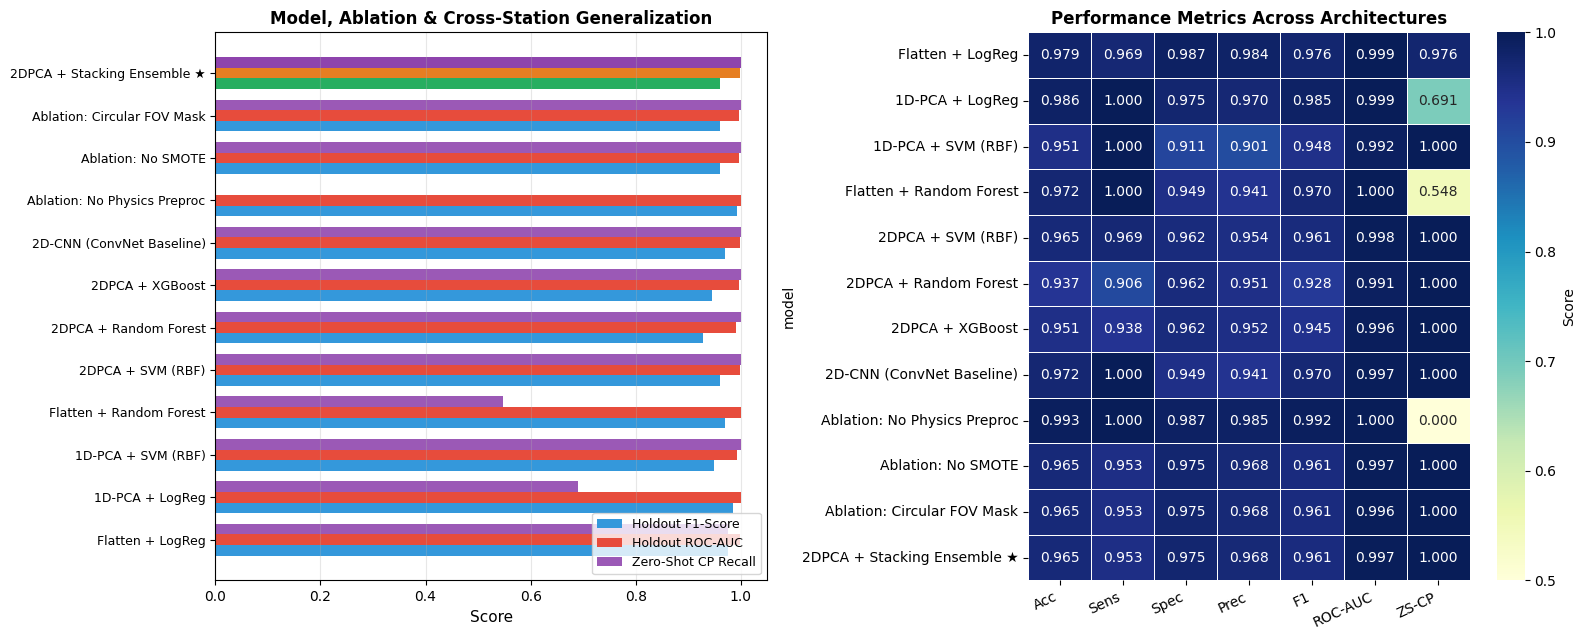

In [13]:
# ========== BASELINE BENCHMARKING, ABLATION & CROSS-STATION GENERALIZATION ==========
fig_bench, df_bench = benchmark_baselines(
    X_train, y_train,
    X_test, y_test,
    n_components=N_COMPONENTS,
    balance_method=BALANCE_METHOD,
    ensemble_params=ENSEMBLE_PARAMS,
    X_train_raw=X_train_raw,
    X_test_raw=X_test_raw,
    X_train_masked=X_train_masked,
    X_test_masked=X_test_masked,
    y_train_orig=y_train_orig,
    X_all=X,
    y_all=y,
    X_all_raw=X_raw,
    X_all_masked=X_masked,
    df_metadata=df_labels,
    include_cnn=True,
    save_path=f"{FIGS_DIR}/benchmark_baselines.png",
    dpi=300
)


In [14]:
# ========== HARD NEGATIVES, LUNAR STRATIFICATION, CROSS-STATION & STAGE 1 QC ==========
gen_results = evaluate_hard_negatives_and_generalization(
    X=X,
    y=y,
    df_metadata=df_labels,
    oof_y_pred=oof_logo["y_pred"],      # leave-one-night-out predictions (primary protocol)
    oof_y_proba=oof_logo["y_proba"],
    oof_label="Leave-One-Night-Out OOF",
    system=system,
    util_dir="util",
    threshold_stars=4500,
)

INFO: Iniciando treinamento do sistema...


INFO: Treinando 2DPCA para extração de features...



🛡️ HARD-NEGATIVE, LUNAR ILLUMINATION & CROSS-STATION GENERALIZATION ANALYSIS

1️⃣ Lunar Illumination Stratification (Leave-One-Night-Out OOF):
                   Regime   N  EPB  No_EPB  Accuracy  Sensitivity  Specificity     F1  FP                                       Note
Low/Moderate Moon (< 50%) 475  255     220    0.4316       0.7725       0.0364 0.5934 212                                           
     Bright Moon (>= 50%)  97    0      97    0.0412          N/A       0.0412    N/A  93 No EPB frames: only Specificity is defined
       All Labeled Images 572  255     317    0.3654       0.7725       0.0379 0.5205 305                                           


INFO: Variância explicada: 59.81%


INFO: Extraindo features...


INFO: Shape das features: (530, 320)


... (33 outputs left out)

INFO: Classe 1: 255 → 255



2️⃣ Zero-Shot Cross-Station Generalization (Train: CA+BJL -> Test: CP):
   • Detected 42/42 EPB frames (100.00% Recall, Mean Confidence: 75.71%)

   Station Breakdown:
                    Station                      Evaluation_Mode   N  EPB  No_EPB  Accuracy                                         Measures
                         CA              Leave-One-Night-Out OOF 310  213      97    0.5129                  Accuracy (both classes present)
                        BJL              Leave-One-Night-Out OOF 220    0     220    0.0364 Specificity only (station has quiet frames only)
                         CP              Leave-One-Night-Out OOF  42   42       0    1.0000   Sensitivity only (station has EPB frames only)
CP (Unseen Station Holdout) Zero-Shot (Trained on CA+BJL, n=530)  42   42       0    1.0000   Sensitivity only (station has EPB frames only)

   ⚠️  Single-class stations: BJL, CP, CP (Unseen Station Holdout).
      For these, 'Accuracy' equals Sensitivity (EPB-only)

INFO: Treinamento concluído!



3️⃣ Stage 1 Sky Quality Control vs. Stage 2 Alone on Nocturnal Sequences:
                             Nocturnal_Sequence  Total_Frames QC_Flagged_Cloudy QC_Degraded Stage2_Only_EPB_Triggers Cascaded_Valid_EPB_Detections Cascaded_ClearSky_EPB
      BJL night 2025-07-22/23 (Clear Quiet Sky)           230         14 (6.1%)    9 (3.9%)                 3 (1.3%)                      0 (0.0%)              0 (0.0%)
CA night 2026-06-24/25 (Cloud-Contaminated Sky)            62        49 (79.0%)   7 (11.3%)               61 (98.4%)                    13 (21.0%)              6 (9.7%)
      CA night 2025-10-22/23 (Active EPB Night)           140          4 (2.9%)    5 (3.6%)              125 (89.3%)                   125 (89.3%)           122 (87.1%)



🔍 FEATURE INTERPRETATION

📸 Imagem: O6_CA_20251023_014643.png
   • True class: EPB
   • Prediction: EPB
   • Probabilidade EPB: 99.15%
   • Confidence: Alta

📊 Most important regions (critical pixels):
   • Upper Left: 145 pixels (35.4%)
   • Lower Left: 140 pixels (34.1%)
   • Upper Right: 81 pixels (19.8%)
   • Lower Right: 44 pixels (10.7%)

💡 Interpretation:
   ✓ The model identified characteristic EPB patterns:
     - Vertical/irregular structures
     - Localized plasma depletions
     - Typical spatial distribution of bubbles


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


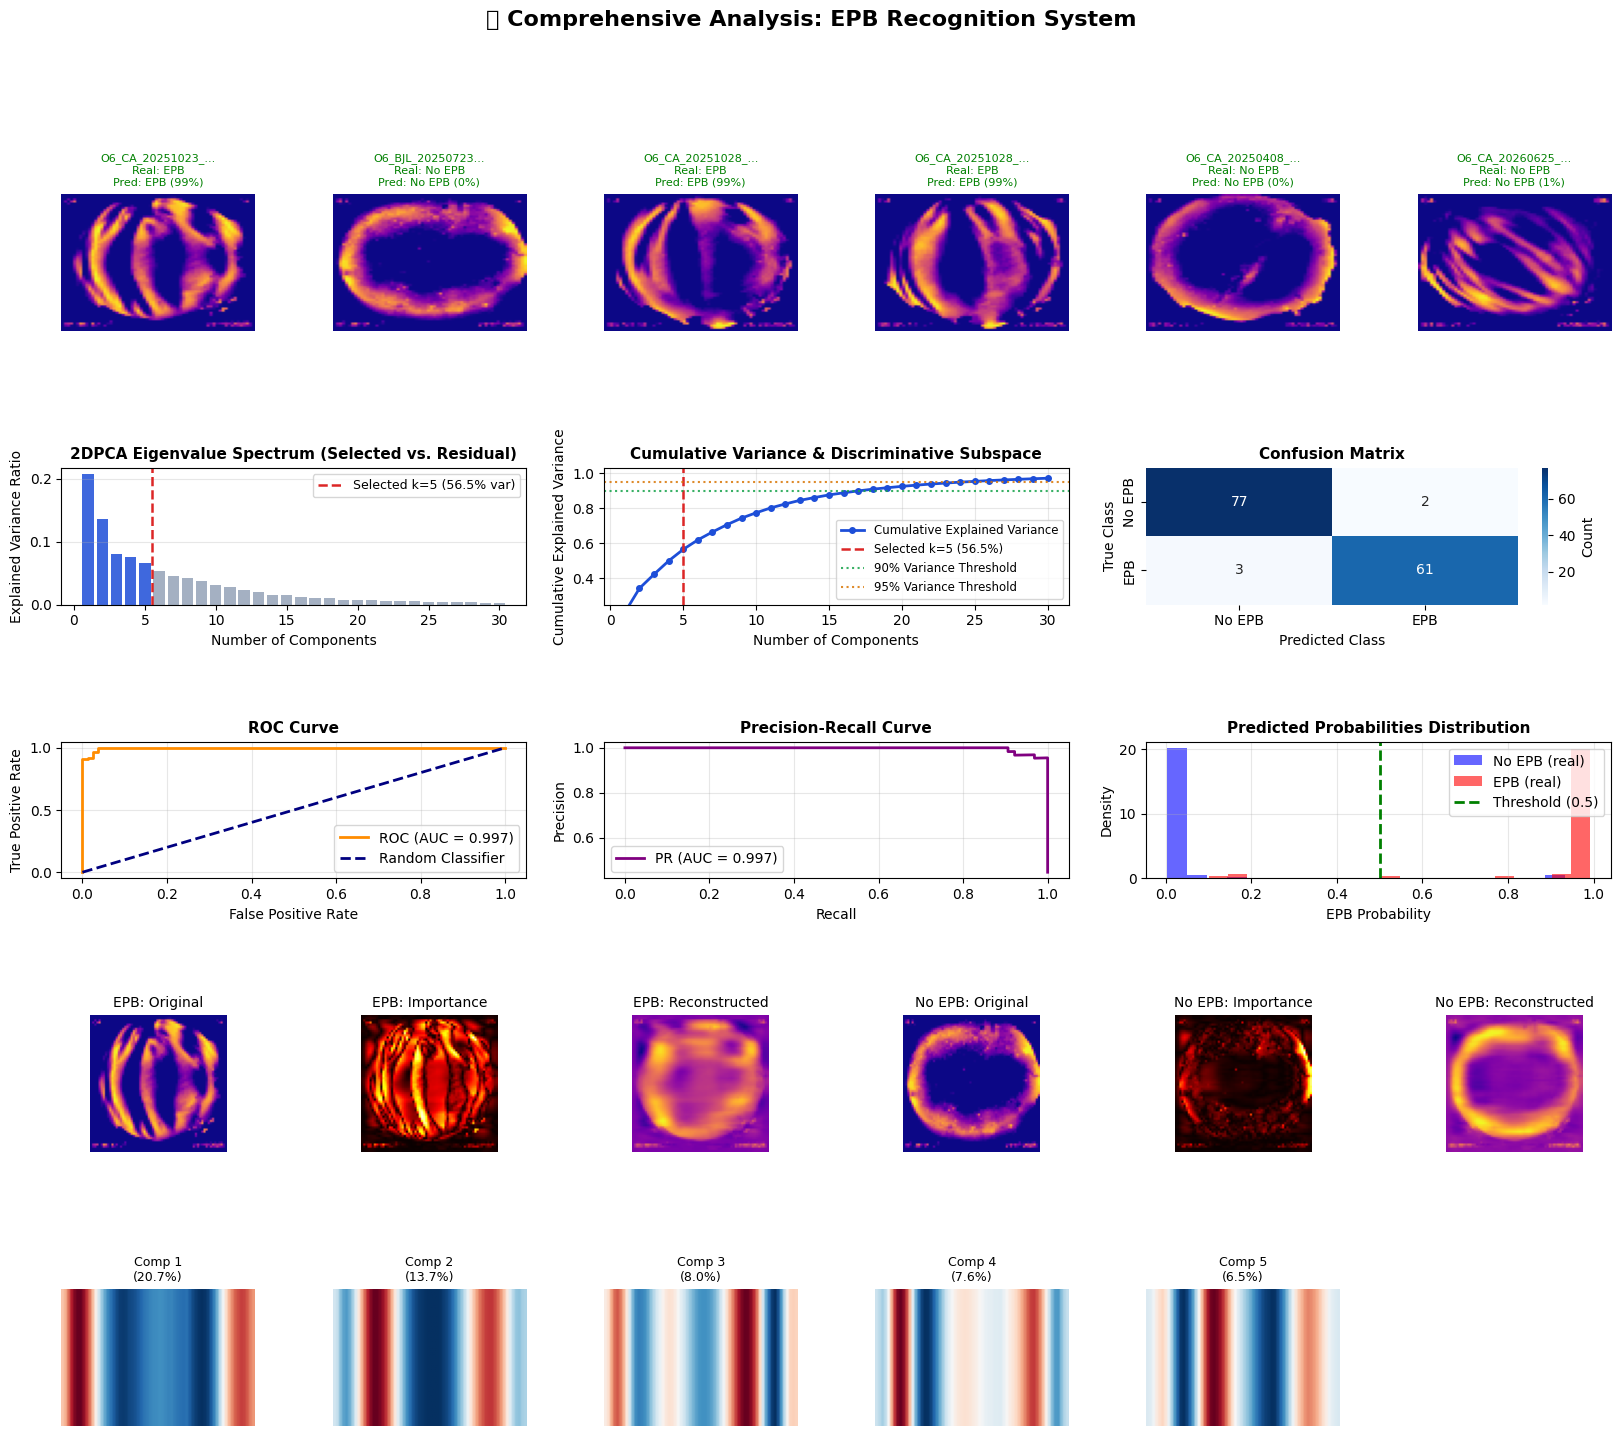

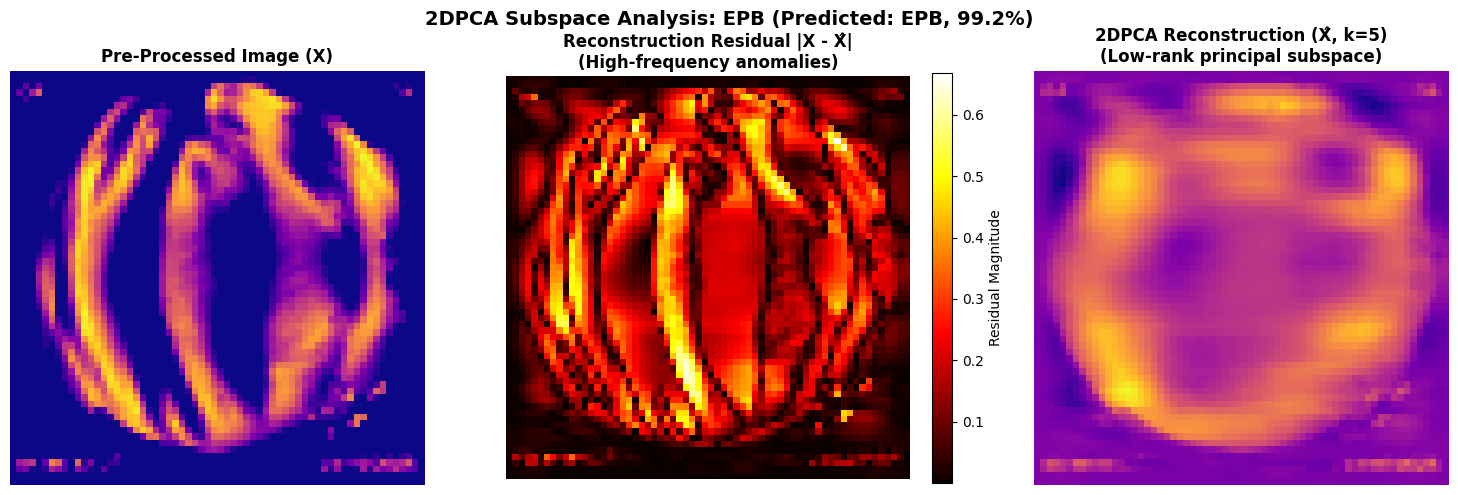

/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



🔬 SHAP EXPLAINABILITY ANALYSIS — Supervised Pixel Attribution

📸 Image: O6_CA_20251023_014643.png
   • True class: EPB
   • Prediction: EPB (99.2%)
   • SHAP Method: TreeExplainer (XGBoost + RF)

📊 SHAP contribution by quadrant:
   • Upper Right: 40.4% (↑ EPB)
   • Upper Left: 37.1% (↑ EPB)
   • Lower Left: 13.2% (↑ EPB)
   • Lower Right: 9.4% (↑ EPB)

📐 Spearman Correlation (|SHAP| vs. 2DPCA Reconstruction Error): 0.532


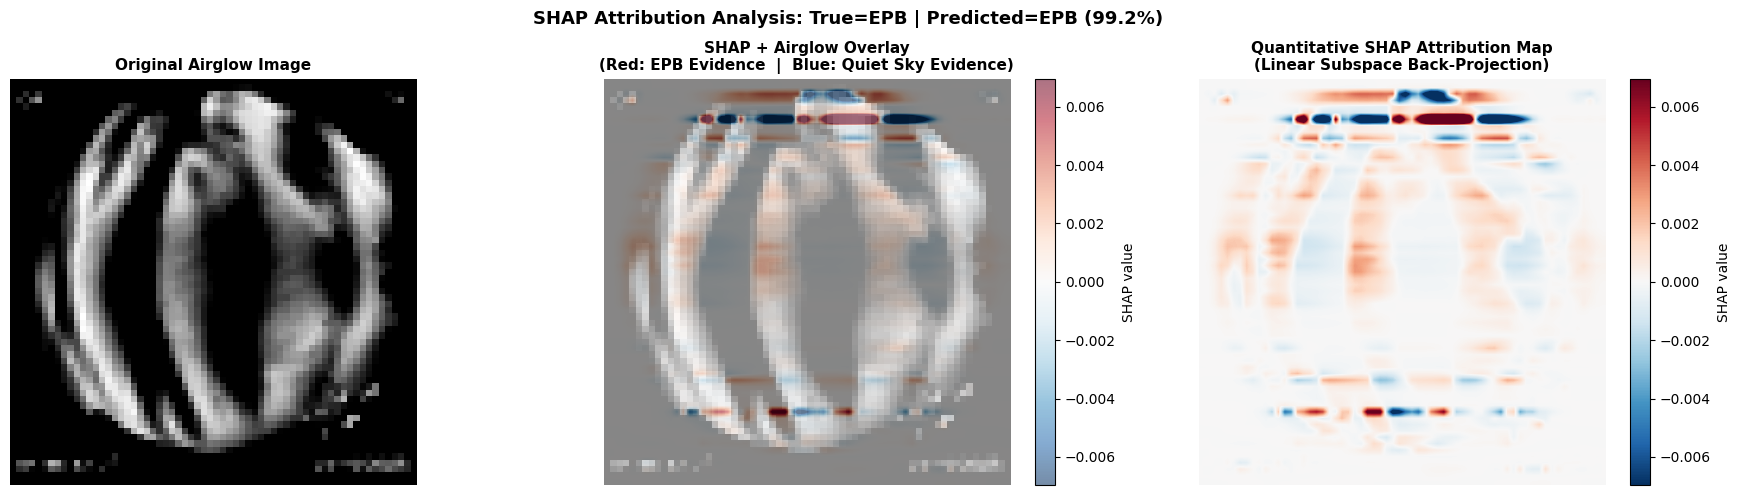

In [15]:
# ========== COMPREHENSIVE DASHBOARD & FEATURE INTERPRETABILITY ==========
plot_comprehensive_analysis(
    system, X_train, X_test, y_train, y_test,
    y_pred, y_proba, files_test
)

epb_correct_idx = np.where((y_test == 1) & (y_pred == 1))[0]
if len(epb_correct_idx) > 0:
    idx = epb_correct_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx], show_filename=False)
    explain_shap_importance(system, X_test[idx], y_test[idx], X_train, files_test[idx], show_filename=False)


In [16]:
# ========== SAVE TRAINED MODEL (V4.0) ==========
print("="*70)
print("SAVING TRAINED MODEL (V4.0)")
print("="*70)

model_data = EPBModelData(
    version=MODEL_VERSION,
    system=system,
    n_components=N_COMPONENTS,
    target_size=TARGET_SIZE,
    test_metrics={
        # Primary: leave-one-night-out (pooled over unseen nights)
        "logo_accuracy": float(res_logo["summary"].set_index("model").loc[PROPOSED]["accuracy"]),
        "logo_sensitivity": float(res_logo["summary"].set_index("model").loc[PROPOSED]["sensitivity"]),
        "logo_specificity": float(res_logo["summary"].set_index("model").loc[PROPOSED]["specificity"]),
        "logo_auc": float(res_logo["summary"].set_index("model").loc[PROPOSED]["auc"]),
        "logo_worst_night_accuracy": float(res_logo["summary"].set_index("model").loc[PROPOSED]["worst_night_accuracy"]),
        # Optimistic references: frame-level holdout and frame-level 5-fold CV
        "accuracy": float(np.mean(y_pred == y_test)),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "ppv": float(ppv),
        "npv": float(npv),
        "cv_f1_mean": float(df_kfold["f1"].mean()),
        "cv_auc_mean": float(df_kfold["auc"].mean()),
    }
)

file_hash = save_model(model_data, f"models/epb_recognition_model-v{MODEL_VERSION}.pkl")
# Each version keeps its own file: do not overwrite older models (v3.0 must stay the v3.0 weights).

print(f"   ✓ Saved model: models/epb_recognition_model-v{MODEL_VERSION}.pkl (v{MODEL_VERSION})")
print(f"   ✓ SHA-256: {file_hash[:16]}...")
print("\n" + "="*70)
print("✅ V4 PIPELINE EXECUTED SUCCESSFULLY!")
print("="*70)

INFO: Modelo salvo: models/epb_recognition_model-v4.0.pkl (SHA-256: 0033b63033e02c22...)


SAVING TRAINED MODEL (V4.0)
   ✓ Saved model: models/epb_recognition_model-v4.0.pkl (v4.0)
   ✓ SHA-256: 0033b63033e02c22...

✅ V4 PIPELINE EXECUTED SUCCESSFULLY!
